## Telemanom Reproduction: P-1

This notebook investigates the original Telemanom anomaly detection pipeline for the P-1 data channel

It begins with the authors' saved predictions and smoothed errors. The goal is to reproduce this detection state before considering changes to their methods



## How the original method detects anomalies

Telemon trains a Long Short-Term Memory (LSTM) model. These models are tools for time series forecasting capable of capturing complex termpral dependecies in data

The LSTM learns to predict telemetry values using previous readings and encoded spacecraft command information. It does not train on anomaly labels.

After prediction, the detection procedure:

1. Calculates the difference between predicted and actual readings.
2. Smooths those errors to reduce rapid fluctuations.
3. Applies a dynamic threshold to identify unusually large errors.
4. Removes some weak candidate alerts to reduce false positives. (So these could be the alerts that just barely exceed the given threshold. The process of removing this is called pruning)

The known anomaly intervals are used afterward to evaluate the detections. These supplied anomaly intervals describe manually labeled time ranges associated with spacecraft indicent, surprise, anomaly (ISA) reports.

The paper [https://arxiv.org/abs/1802.04431] describes an expert review but does not give precise rules for every intervals endpoints. A normal looking individual reading can therefore lie within a labeled anomaly sequence

Under the authors event based evaluation, a labeled event counts as detected when a predicted anomaly sequence overlaps any part of it. Detecting an event does not require flagging every reading inside it.

## Saved files and reference result

The dataset includes a saved run named `2018-05-19_15.00.10` containing:

- `models/P-1.h5`: the pretrained neural network.
- `y_hat/P-1.npy`: saved telemetry predictions.
- `smoothed_errors/P-1.npy`: saved smoothed prediction errors.
- `params.log`: settings and results recorded for the run.

The log records the following two settings: `train: False` and `predict: False`

These tell the program which steps to skip. For example,

`train: False` means "dont train a new neural network"

`predict: False` means "dont generate new predictions, load previously saved predictions"


For P-1 the saved run reports the following:

| Event-level outcome | Count |
|---|---:|
| True positives | 2 |
| False positives | 1 |
| False negatives | 1 |



## Interpreting the recorded P-1 Results

There are 2 true positives (TP), 1 false positive (FP), and 1 false negative (FN)

**Event precision** measures how many detections were correct:

$$
\mathrm{Precision} = \frac{TP}{TP+FP}
= \frac{2}{3} \approx 66.7\%.
$$

**Event recall** measures how many known events were detected:

$$
\mathrm{Recall} = \frac{TP}{TP+FN}
= \frac{2}{3} \approx 66.7\%.
$$

Two of P-1's three labeled events were detected, one was missed,
and one false alert sequence was reported. Again, under the authors' scoring
rule, overlap with any part of a labeled interval counts as detecting
that event and every reading inside it need not be flagged.


Before plotting or evaluating the saved arrays, we will check how their
indices align with the original test readings.

In [1]:
from pathlib import Path
import numpy as np

# load the data
repo_dir = Path.cwd().parent
data_dir = repo_dir / "data" / "data"
run_dir = data_dir / "2018-05-19_15.00.10"


p1_test = np.load(data_dir / "test" / "P-1.npy")
p1_predictions = np.load(run_dir / "y_hat" / "P-1.npy")
p1_smoothed_errors = np.load(run_dir / "smoothed_errors" / "P-1.npy")

# show P-1 saved predicions and smoothed errors
print("Test data shape:", p1_test.shape)
print("Saved predictions shape:", p1_predictions.shape)
print("Saved smoothed errors shape:", p1_smoothed_errors.shape)

Test data shape: (8505, 25)
Saved predictions shape: (8245,)
Saved smoothed errors shape: (8245,)


#### There are 8505 test readings, but only 8245 saved predictions. We need to know which readings belong with each prediction 

Looking at the file
- `params.log`
We know that their model needs 250 readings before it can predict anything, and another 10 readings are needed for a prediction target window


Since each saved prediction is a prediction for a particular test reading, use the following code to pair each saved prediction with the actual test reading it predicts

In [2]:
# Define this to make the first prediction come after the first 250
history_length = 250

# This creates 8245 consecutive indicies, starting at 250
# np.arange to exclude the ending value
prediction_indices = np.arange(
history_length,
history_length + len(p1_predictions))


# this selects the actual telemetry readings at test indicies 250, 251, ..., 8494
actual_aligned = p1_test[prediction_indices, 0]


# checks that we have one actual reading for every saved prediction
assert len(actual_aligned) == len(p1_predictions)
assert len(p1_smoothed_errors) == len(p1_predictions)

print("First corresponding test index:", prediction_indices[0])
print("Last corresponding test index:", prediction_indices[-1])
print("Aligned readings:", len(actual_aligned))

First corresponding test index: 250
Last corresponding test index: 8494
Aligned readings: 8245


### Plot the actual readings alongside the saved predictions to see how closely the model follows the telemetry

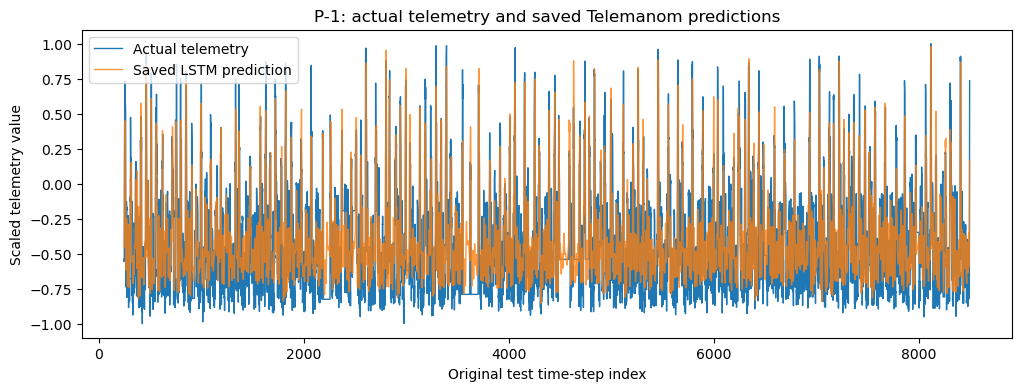

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    prediction_indices,
    actual_aligned,
    label="Actual telemetry",
    linewidth=1
)

ax.plot(
    prediction_indices,
    p1_predictions,
    label="Saved LSTM prediction",
    linewidth=1,
    alpha=0.8
)

ax.set_xlabel("Original test time-step index")
ax.set_ylabel("Scaled telemetry value")
ax.set_title("P-1: actual telemetry and saved Telemanom predictions")
ax.legend()

plt.show()

### Their saved predictions in y_hat seem to mach the data closely, but plot over known anomaly interval for another quick inspection

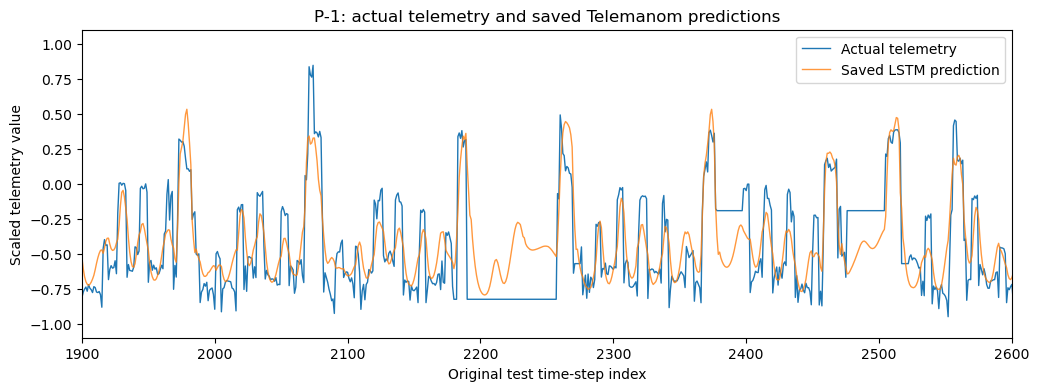

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    prediction_indices,
    actual_aligned,
    label="Actual telemetry",
    linewidth=1
)

ax.plot(
    prediction_indices,
    p1_predictions,
    label="Saved LSTM prediction",
    linewidth=1,
    alpha=0.8
)

ax.set_xlabel("Original test time-step index")
ax.set_ylabel("Scaled telemetry value")
ax.set_xlim(1900, 2600)

ax.set_title("P-1: actual telemetry and saved Telemanom predictions")
ax.legend()

plt.show()

The authors detect anomalies from prediction errors and not directly from the telemetry values. A good next step would be to calculate the raw prediction error

$$e_t = | y_t - \hat{y}_t |$$

which calculates how far the models prediction misses the true reading at each time step, before reproducing their smoothing step



In [5]:
raw_errors = np.abs(actual_aligned - p1_predictions)

### Plot of raw errors vs supplied smoothed errors

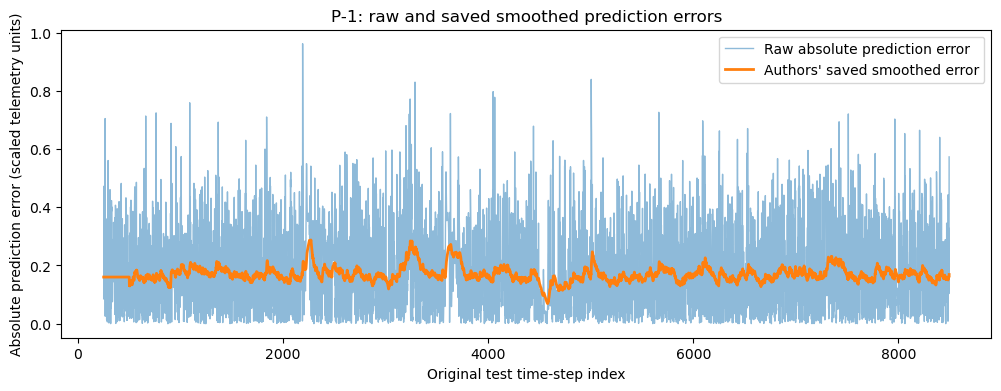

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    prediction_indices,
    raw_errors,
    label="Raw absolute prediction error",
    alpha=0.5,
    linewidth=1
)

ax.plot(
    prediction_indices,
    p1_smoothed_errors,
    label="Authors' saved smoothed error",
    linewidth=2
)

ax.set_xlabel("Original test time-step index")
ax.set_ylabel("Absolute prediction error (scaled telemetry units)")
ax.set_title("P-1: raw and saved smoothed prediction errors")
ax.legend()

plt.show()

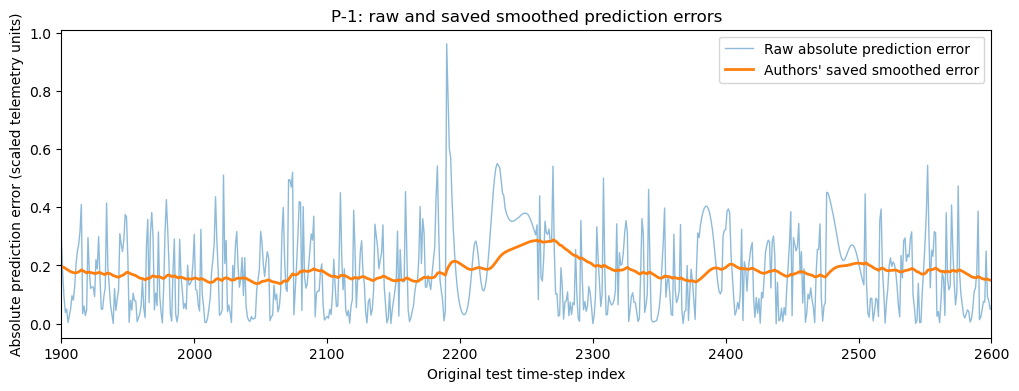

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    prediction_indices,
    raw_errors,
    label="Raw absolute prediction error",
    alpha=0.5,
    linewidth=1
)

ax.plot(
    prediction_indices,
    p1_smoothed_errors,
    label="Authors' saved smoothed error",
    linewidth=2
)

ax.set_xlabel("Original test time-step index")
ax.set_xlim(1900, 2600)

ax.set_ylabel("Absolute prediction error (scaled telemetry units)")
ax.set_title("P-1: raw and saved smoothed prediction errors")
ax.legend()

plt.show()

#### These plots show why smoothing is useful before threshholding

Across the full sequence, raw errors contain frquent sharp spikes and the smooth errors form a more steady curve. Around the known anomlay interval, the raw error spikes while the smooth error shows a relative peak slightly after the agressive spike. 

**This illustrates a tradeoff !**

Smoothing can supress sudden spikes, but can delay and spread out the response to a change

### Reproduction of their smoothing calculation

Relevant code is inside 
-`errors.py`

It does three things
1. Calculates absolute prediction errors (which we have just done)
2. Applies an exponentially weighted moving average (line 58)
3. For P-1, replaces the first 250 smoothed errors with the average of the first 500 smoothed errors


#### Note to self on Exponentially Weighted Moving Averages (EWMA)


EWMA smoothes a sequence by giving recent values more weight than older ones. (It sounds like the SES forecasting I tried to do in my other notebook)

Comparison between the SES I tried and the EWMA the authors did

| | SES work | Authors’ error smoothing |
|---|---|---|
| **Input** | Telemetry readings | Absolute LSTM prediction errors |
| **Purpose** | Forecast the next reading | Identify sustained prediction errors |
| **Next step** | Compare forecast with actual reading | Apply thresholds to identify candidate anomalies |


The basic recursive form of EWMA is as follows:

$$s_t = \alpha e_t + (1 - \alpha)s_{t - 1}$$

where $e_t$ is the current error and $s_{t - 1}$ summarizes earlier errors. $\alpha$ still smoothing parameter that when large has a faster response/more sensitivity to individual fluctuations.

In [8]:
import pandas as pd

# using the settings recorded in params.log
batch_size = 70
window_size = 30
smoothing_perc = 0.05
history_length = 250

# calculate the span used for exponential smoothing
smoothing_span = int(batch_size * window_size * smoothing_perc)


# Smooth our absolute prediction errors
# and convert pd series to Nuumpy array for later comparison with their p1_smoothed_errors file
reproduced_smoothed_errors = (
pd.Series(raw_errors)
.ewm(span=smoothing_span, adjust=True)
.mean()
.to_numpy(copy=True) #copy=True creates a writable copy. w/o it the code fails 
)

# Reproduce the authors' initial-value adjustment for P-1 (line 62 in errors.py)
# l_s = 250 for p1
# note that code does not explain why they chose these particular lengths
reproduced_smoothed_errors[:history_length] = np.mean(
reproduced_smoothed_errors[:2 * history_length])


# Report smoothing setting
print("Smoothing span:", smoothing_span)

# compares my reproduced errors with their saved errors
# comparison is position by position, and reports largest discrepancy
# value of zero means every value matches exactly
print("Maximum absolute difference:",
    np.max(np.abs(reproduced_smoothed_errors - p1_smoothed_errors)))
print("Arrays approximately match:",
np.allclose(reproduced_smoothed_errors, p1_smoothed_errors))

Smoothing span: 105
Maximum absolute difference: 0.0
Arrays approximately match: True


### Apply their dynamic thresholds to these soomthed errors to identify candidate anomaly intervals 

In the
-`errors.py` file

In line (269), it defines a function called find_epsilon() inside the ErrorWindow class 

Conceptually it
1. Takes a window of the smoothed prediction errors

2. Tries candidate threshold of the form

$$\epsilon = \text{mean error} + z \times \text{standard deviation}$$

where z is a multiplier that determines how many standard deviations above the mean the threshold sits. Choosing larger z creates higher threshold, so fewer errors exceed it. The authors try different values of z and select one using their scoring rule (explained below)

3. Scores each candidate by asking "Does removing the large errors substantially reduce the remaining errors' mean and spread, without generating too many flagged readings?"

4. Selects best candidate under that scoring rule

It is called dynamic because the calculation is repeated for successive windows, allowing the threshold to change as the errors change. Note that the known anomaly intervals are not used to choose this alert threshold


### Dynamic threshold selection

The authors try thresholds of the form

$$
\epsilon = \mu + z\sigma,
$$

where $\mu$ and $\sigma$ are the mean and standard deviation of the smoothed errors in the current window, and $z$ controls how high the threshold sits above the mean.

For each candidate threshold, they calculate:

$$
\text{Score} =
\frac{
\text{fractional decrease in mean}
+
\text{fractional decrease in standard deviation}
}{
N_{\text{sequences}}^2 + N_{\text{flagged readings}}
}.
$$

Here is what that means:

- Numerator: Temporarily remove errors at or above the candidate threshold. How much do the remaining errors’ mean and standard deviation decrease? A large decrease suggests the removed errors were substantially different from the rest

- Denominator: Penalize candidates that produce many flagged readings or many separate alert sequences. The sequence count is squared, making numerous separate alerts especially costly. These counts include the neighboring readings added by their error buffer

The highest scoring candidate is selected, subject to limits on the number of flagged readings and sequences. This calculation repeats across successive windows, allowing the threshold to change.

**Known anomaly labels are not used to select the threshold.** They are used afterward to evaluate detections. We will reproduce this procedure before considering changes.

## Construction of the first window of smoothed errors and calculation of its candidate thresholds

Again, the saved settings specify 30 batches of 70 readings, giving 2100 errors per window


In [9]:
# First window used for threshold selection
error_window_length = batch_size * window_size
first_window_errors = reproduced_smoothed_errors[:error_window_length]

# Summarize the errors in this window
mean_error = np.mean(first_window_errors)
std_error = np.std(first_window_errors)

# Candidate multipliers used in the authors' code
z_values = np.arange(2.5, 12.0, 0.5)

candidate_thresholds = pd.DataFrame({
    "z": z_values,
    r"threshold ($\epsilon$)": mean_error + z_values * std_error})

print("Errors in first window:", len(first_window_errors))
print("Mean smoothed error:", mean_error)
print("Standard deviation:", std_error)

candidate_thresholds

Errors in first window: 2100
Mean smoothed error: 0.1713606402238788
Standard deviation: 0.02318839490243396


,z,threshold ($\epsilon$)
0,2.5,0.229332
1,3.0,0.240926
2,3.5,0.252520
3,4.0,0.264114
4,4.5,0.275708
5,5.0,0.287303
6,5.5,0.298897
7,6.0,0.310491
8,6.5,0.322085
9,7.0,0.333679


## Score these values 

$$
\textrm{score} = \frac{\frac{\mu - \mu_{\rm remaining }}{\mu}+\frac{\sigma - \sigma_{\rm remaining}}{\sigma}}{N^2_{\rm sequences} + N_{\rm flagged \ readings}}
$$

(code omits thresholds that have no errors at or above them, so some larger z values may be absent)

In [10]:
error_buffer = 100  # Setting recorded in params.log
# During threshold selection, the authors include up to 99 neighboring positions
# on each side of every error that exceeds the threshold


score_rows = []


# This loop tries one candidate threshold at a time, calculates the score, an records check pass
for z in z_values:
    epsilon = mean_error + z * std_error

    # Errors remaining after removing those at or above the threshold
    # we ask how much their mean and std decrease
    remaining_errors = first_window_errors[first_window_errors < epsilon]

    # Positions of errors at or above the threshold
    # np.flatnonzero -> returns the integer indices of the elements that are non-zero in a 
    # flattened version of the input array
    flagged_indices = np.flatnonzero(first_window_errors >= epsilon)

    # If nothing exceeds this threshold, skip and try next z
    if len(flagged_indices) == 0:
        continue

    # An anomaly can affect a stretch of time
    # adding a buffer with these offests helps group nearby exceedances into ONE EVENT
    # Create offests from -99 to +99, include 0
    offsets = np.arange(-(error_buffer - 1), error_buffer)
    
    
    # Now expand each flagged position into a surrounding interval
    # EX: a flagged position of 200 expands to positions 101-299
    # So position 200 becomes a candidate interval covering 101 - 299
    # If another error exceeds the threshold nearby, its surrounding interval may overlap this one
    # combining these positions can turn several nearby exceedances into one continous alert
    
    # [: None] makes each flagged position a separate row so NumPy can add offests to it
    # .ravel() then combines the resulting rows into one flat array
    buffered_indices = (
        flagged_indices[:, None] + offsets).ravel()

    
    # Keep valid, unique positions within this window
    # overlaping buffers can repreat positions
    # np.unique removes duplicates and sorts the positions
    buffered_indices = np.unique(buffered_indices[
        (buffered_indices >= 0) & (buffered_indices < len(first_window_errors))])

    # Group consecutive positions into sequences
    groups = np.split(buffered_indices, np.flatnonzero(np.diff(buffered_indices) > 1) + 1)
    
    
    # count groups containing at least two positions
    # the authors exclude single position groupd from the sequence count
    n_sequences = sum(len(group) > 1 for group in groups)
    
    # count all unique positions included after buffering
    n_flagged = len(buffered_indices)

    mean_decrease = (
        mean_error - np.mean(remaining_errors)
    ) / mean_error

    std_decrease = (
        std_error - np.std(remaining_errors)
    ) / std_error

    score = (
        mean_decrease + std_decrease
    ) / (n_sequences**2 + n_flagged)

    # Authors' limits on candidate alerts
    eligible = (
        n_sequences <= 5
        and n_flagged < 0.5 * len(first_window_errors)
    )

    score_rows.append({
        "z": z,
        "threshold": epsilon,
        "flagged with buffer": n_flagged,
        "sequences": n_sequences,
        "score": score,
        "eligible": eligible
    })

    
# Convert the collected dictionaries into a table.

threshold_scores = pd.DataFrame(score_rows)
threshold_scores

,z,threshold,flagged with buffer,sequences,score,eligible
0,2.5,0.229332,219,1,0.001346,True
1,3.0,0.240926,216,1,0.001262,True
2,3.5,0.252520,211,1,0.001149,True
3,4.0,0.264114,205,1,0.000980,True
4,4.5,0.275708,199,1,0.000733,True
5,5.0,0.287303,179,1,0.000034,True


#### Note on authors eligibility on candidate alerts

These are two limits the authors impose before a candidate threshold can be selected:
1. No more than five sequences: After adding buffers and grouping connected positions, there must be at most five separate candidate alert intervals.
2. Less than half the window flagged: Our window contains 2,100 readings, so fewer than 1,050 positions, including buffers, can be flagged


In the table above, the column **flagged with buffer** reports the number of unique positions included after expanding the threshold exceedances with neighboring positions

**sequences** reports the number of separate continuous candidate alert interval after buffering

Ex. If the sequence is the following uninterrupted group of flagged positions after adding the buffers

[100, 101, 102, 103, 400, 401, 402]

There are two sequences:
- Positions 100–103
- Positions 400–402
The gap between 103 and 400 separates them.

So flagged with buffer would be 7, while sequences would be 2. One counts individual positions; the other counts the continuous intervals those positions form.

#### The highest score belongs to $z=2.5$, giving a threshold of approximately 0.229332. All candidates are eligible, so this is the winner for our first window 

(Once again where window refers to the first 2100 smoothed prediction errors. Comes from length settings 70 readings per batch * 30 batches. Later, their algorithm moves the window forward and recalculates the threshold, this is what makes it dynamic)

plot it against the smoothed errors

Selected z: 2.5
Selected threshold: 0.22933162747996372


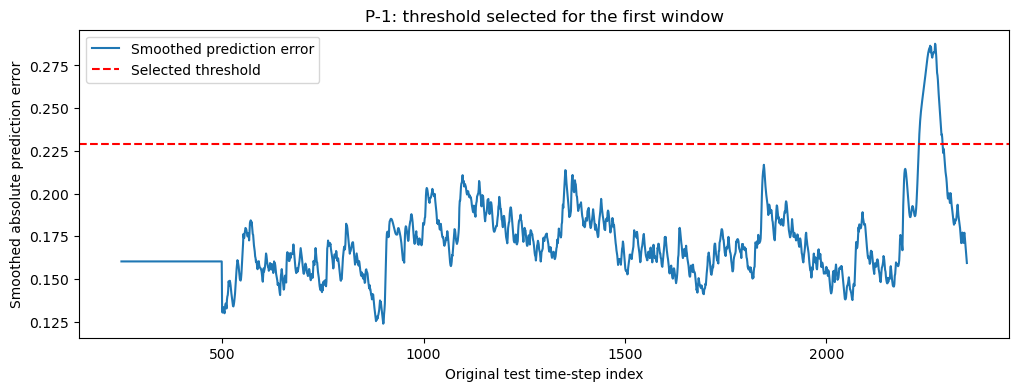

In [11]:
# Keep eligible candidates and select the one with the highest score
eligible_candidates = threshold_scores.loc[threshold_scores["eligible"]]

best_candidate = eligible_candidates.loc[
    eligible_candidates["score"].idxmax()]

selected_threshold = best_candidate["threshold"]

print("Selected z:", best_candidate["z"])
print("Selected threshold:", selected_threshold)

# Original test indices corresponding to this first error window
window_indices = prediction_indices[:len(first_window_errors)]

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    window_indices,
    first_window_errors,
    label="Smoothed prediction error"
)

ax.axhline(
    selected_threshold,
    color="red",
    linestyle="--",
    label="Selected threshold"
)

ax.set_xlabel("Original test time-step index")
ax.set_ylabel("Smoothed absolute prediction error")
ax.set_title("P-1: threshold selected for the first window")
ax.legend()
plt.show()

The plot shows that only the large peak near test index 2250 exceeds the selected threshold of approximately 0.2293. Most smoothed errors remain below it.

That peak falls within P-1’s first known anomaly interval, 2149–2349. This is promising, but it is still a candidate detection

The flat section at the beginning comes from the authors’ initial value adjustment that we reproduced

We must apply the remaining detection checks, buffering, and pruning before counting it as a reproduced result.

-`errors.py` line 324

Next, we’ll reproduce the size checks in their compare_to_epsilon() function. These prevent very small errors from generating alerts merely because they exceed a low threshold

First, reconstruct the actual telemetry targets for this window. Their code uses all 10 targets per prediction window when calculating the telemetry’s spread:

In [12]:
# Reconstruct the 10 actual targets associated with each prediction
target_indices = (window_indices[:, None] + np.arange(10))

window_targets = p1_test[target_indices, 0]

# Measure the spread of the actual telemetry
telemetry_std = np.std(window_targets)
percentile_5, percentile_95 = np.percentile(window_targets, [5, 95])
telemetry_range = percentile_95 - percentile_5

# Authors' check: are the smoothed errors large enough to consider?
passes_size_check = (
    (
        std_error > 0.05 * telemetry_std
        or np.max(first_window_errors) > 0.05 * telemetry_range
    )
    and np.max(first_window_errors) > 0.05
)

# Keep positions satisfying both the selected threshold and size requirement
if passes_size_check:
    candidate_positions = np.flatnonzero(
        (first_window_errors >= selected_threshold)
        & (first_window_errors > 0.05 * telemetry_range)
    )
else:
    candidate_positions = np.array([], dtype=int)

print("Window passes error-size check:", passes_size_check)
print("Candidate readings before buffering:", len(candidate_positions))

Window passes error-size check: True
Candidate readings before buffering: 59


### Buffering and grouping candidate alerts

The 59 candidate readings passed both the selected threshold and the authors’ error size requirement 

We now expand each candidate position by **100 readings on either side**, keeping positions within the current window

For P-1’s first window, the authors also exclude the first **500 error positions** from detection. Finally, we convert the interval boundaries to original test indices so we can compare them with the labeled anomalies.

These intervals are **candidates before pruning**, not final detections.

In [13]:
# Detection uses 100 neighboring positions on each side.
# Their threshold-scoring code used 99 on each side.
offsets = np.arange(-error_buffer, error_buffer + 1)

buffered_positions = (candidate_positions[:, None] + offsets).ravel()

# Keep unique positions within this window
buffered_positions = np.unique(buffered_positions[
    (buffered_positions >= 0) & (buffered_positions < len(first_window_errors))])

# For P-1's first window, the authors ignore the first 500 error positions
buffered_positions = buffered_positions[buffered_positions >= 2 * history_length]

# Separate the positions wherever there is a gap
groups = np.split(buffered_positions,np.flatnonzero(np.diff(buffered_positions) > 1) + 1)

# Keep continuous sequences containing at least two positions
candidate_intervals = [
    (int(group[0]), int(group[-1]))
    for group in groups
    if len(group) > 1]

# Convert positions within the window to original test indices
candidate_test_intervals = [
    (int(window_indices[start]), int(window_indices[end]))
    for start, end in candidate_intervals]

print("Buffered candidate readings:", len(buffered_positions))
print("Candidate intervals in original test indices:", candidate_test_intervals)

Buffered candidate readings: 220
Candidate intervals in original test indices: [(2130, 2349)]


The 59 candidate readings expanded into one continuous interval covering 220 readings, from test index 2130 to 2349

It overlaps the known anomaly interval 2149–2349, extending 19 readings earlier because of buffering

The next step is pruning which is checking whether this candidate’s peak error stands out enough from errors outside the candidate interval to retain it

### Pruning weak candidate alerts

For our single candidate interval, we compare its peak smoothed error with the largest smoothed error outside the buffered interval:

$$
\text{Relative separation}
=
\frac{\text{candidate peak}-\text{largest outside error}}
{\text{candidate peak}}.
$$

The saved pruning setting is $p=0.13$. We retain the candidate if its relative separation is at least **13%**; otherwise, we remove it.

This checks whether the candidate stands out sufficiently from the surrounding errors. It does not use the known anomaly labels.

In [14]:
# Pruning setting from params.log
p = 0.13

# Our first window contains one candidate interval
start, end = candidate_intervals[0]

# Largest smoothed error inside the candidate interval
candidate_peak = np.max(first_window_errors[start:end + 1])

# Identify positions outside the buffered candidate interval
outside_mask = np.ones(len(first_window_errors), dtype=bool)
outside_mask[buffered_positions] = False

# Largest smoothed error outside the candidate interval
outside_peak = np.max(first_window_errors[outside_mask])

# Measure how clearly the candidate peak stands apart
relative_separation = (
    candidate_peak - outside_peak
) / candidate_peak

keep_candidate = relative_separation >= p

print("Candidate peak:", candidate_peak)
print("Largest outside error:", outside_peak)
print(f"Relative separation: {relative_separation:.1%}")
print("Keep candidate:", keep_candidate)

Candidate peak: 0.2877370447817612
Largest outside error: 0.2168724668845143
Relative separation: 24.6%
Keep candidate: True


#### Again. Make sure it is clear what the cell above does

It divides the first window into two parts:
- Inside our candidate interval, test indices 2130–2349: the highest smoothed error is 0.2877
- Everywhere else in that window: the highest smoothed error is 0.2169


Then it compares these two peaks to ask: Does the candidate contain an error that stands out clearly from everything outside it?

Here, their difference is 24.6% of the candidate peak, which exceeds the authors’ 13% requirement, so we keep the candidate

### Following the authors convention, its time to check for unusually low errors

Why?

A malfunction can produce unusually small prediction errors. For example, a sensor stuck at a constant value may become easy to predict, so a detector looking only for large errors could miss it

The authors also search for unusually low errors by reflecting the smoothed errors around their mean:

$$
e_t^{\mathrm{inv}} = 2\mu - e_t.
$$

This turns low values into high values, allowing the same threshold procedure to detect them. It changes neither the time positions nor the information available. It is a way to implement a lower tail search. 

Plot the inverse for added visual showing how low errors become high errors after inversion. **The reason for this inversion is to let the ssame detection procedure search for unusually low errors**

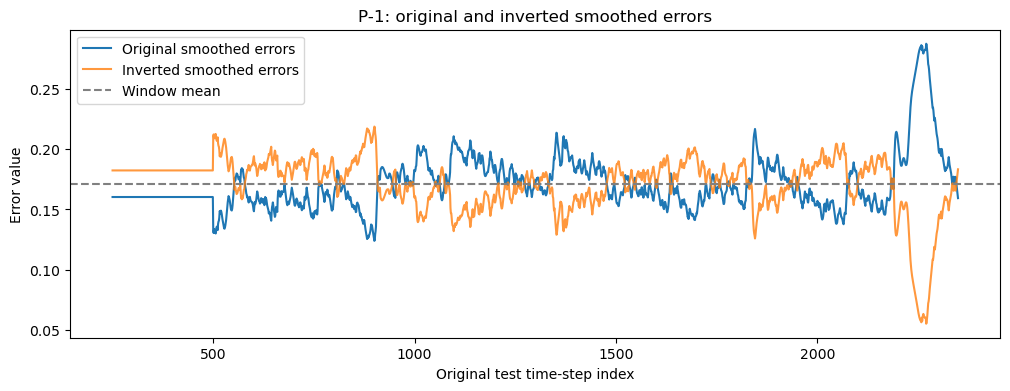

In [15]:
# Reflect the first window's smoothed errors around their mean
first_window_inverted = 2 * mean_error - first_window_errors

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    window_indices,
    first_window_errors,
    label="Original smoothed errors"
)

ax.plot(
    window_indices,
    first_window_inverted,
    label="Inverted smoothed errors",
    alpha=0.8
)

ax.axhline(
    mean_error,
    color="gray",
    linestyle="--",
    label="Window mean"
)

ax.set_xlabel("Original test time-step index")
ax.set_ylabel("Error value")
ax.set_title("P-1: original and inverted smoothed errors")
ax.legend()
plt.show()

In [16]:
# First window used for threshold selection
error_window_length = batch_size * window_size
first_window_errors = reproduced_smoothed_errors[:error_window_length]

# Summarize the errors in this window
mean_error = np.mean(first_window_errors)
std_error = np.std(first_window_errors)

# Reflect errors around their mean

first_window_inverted = 2* mean_error - first_window_errors

# Candidate multipliers used in the authors' code
z_values = np.arange(2.5, 12.0, 0.5)

inverted_candidate_thresholds = pd.DataFrame({
    "z": z_values,
    r"threshold ($\epsilon$)": mean_error + z_values * std_error})

print("Errors in first window:", len(first_window_inverted))
print("Mean smoothed error:", mean_error)
print("Standard deviation:", std_error)

inverted_candidate_thresholds


inverted_score_rows = []


# This loop tries one candidate threshold at a time, calculates the score, an records check pass
for z in z_values:
    epsilon = mean_error + z * std_error

    # Errors remaining after removing those at or above the threshold
    # we ask how much their mean and std decrease
    remaining_errors = first_window_inverted[first_window_inverted < epsilon]

    # Positions of errors at or above the threshold
    # np.flatnonzero -> returns the integer indices of the elements that are non-zero in a 
    # flattened version of the input array
    flagged_indices = np.flatnonzero(first_window_inverted >= epsilon)

    # If nothing exceeds this threshold, skip and try next z
    if len(flagged_indices) == 0:
        continue

    # An anomaly can affect a stretch of time
    # adding a buffer with these offests helps group nearby exceedances into ONE EVENT
    # Create offests from -99 to +99, include 0
    offsets = np.arange(-(error_buffer - 1), error_buffer)
    
    
    # Now expand each flagged position into a surrounding interval
    # EX: a flagged position of 200 expands to positions 101-299
    # So position 200 becomes a candidate interval covering 101 - 299
    # If another error exceeds the threshold nearby, its surrounding interval may overlap this one
    # combining these positions can turn several nearby exceedances into one continous alert
    
    # [: None] makes each flagged position a separate row so NumPy can add offests to it
    # .ravel() then combines the resulting rows into one flat array
    buffered_indices = (
        flagged_indices[:, None] + offsets).ravel()

    
    # Keep valid, unique positions within this window
    # overlaping buffers can repreat positions
    # np.unique removes duplicates and sorts the positions
    buffered_indices = np.unique(buffered_indices[
        (buffered_indices >= 0) & (buffered_indices < len(first_window_inverted))])

    # Group consecutive positions into sequences
    groups = np.split(buffered_indices, np.flatnonzero(np.diff(buffered_indices) > 1) + 1)
    
    
    # count groups containing at least two positions
    # the authors exclude single position groupd from the sequence count
    n_sequences = sum(len(group) > 1 for group in groups)
    
    # count all unique positions included after buffering
    n_flagged = len(buffered_indices)

    mean_decrease = (
        mean_error - np.mean(remaining_errors)
    ) / mean_error

    std_decrease = (
        std_error - np.std(remaining_errors)
    ) / std_error

    score = (
        mean_decrease + std_decrease
    ) / (n_sequences**2 + n_flagged)

    # Authors' limits on candidate alerts
    eligible = (
        n_sequences <= 5
        and n_flagged < 0.5 * len(first_window_inverted)
    )

    inverted_score_rows.append({
        "z": z,
        "threshold": epsilon,
        "flagged with buffer": n_flagged,
        "sequences": n_sequences,
        "score": score,
        "eligible": eligible
    })

    
# Convert the collected dictionaries into a table.

inverted_threshold_scores = pd.DataFrame(inverted_score_rows)
inverted_threshold_scores

Errors in first window: 2100
Mean smoothed error: 0.1713606402238788
Standard deviation: 0.02318839490243396


""


The empty table means none of the inverted errors reached any candidate threshold, so every loop iteration hit continue without adding a row.

The lowest threshold was approximately 0.2293. In the original error curve, exceeding that inverted threshold would require:

$$
e_t \leq 2(0.17136)-0.22933 \approx 0.11339.
$$

No smoothed errors were that low in this window. Therefore, this window produces no low error candidates under the authors’ threshold search

### Retain high error candidate and extend procedure across the remaining windows

Map out all windows before applying detection procedure to each one 

# **(idea for later could consider different machine learning algorithims at each window. see what happens)**

In [17]:
n_errors = len(reproduced_smoothed_errors)
window_length = batch_size * window_size

# Number of window advances used by the authors
n_advances = (n_errors - window_length) // batch_size

window_rows = []

for window_number in range(n_advances + 1):
    start = window_number * batch_size
    stop = start + window_length

    # Include all remaining errors in the final window
    if window_number == n_advances:
        stop = n_errors

    window_rows.append({
        "window": window_number,
        "start": start,
        "stop": stop,
        "error values in window": stop - start,
        "first test index": prediction_indices[start],
        "last test index": prediction_indices[stop - 1]
    })

windows = pd.DataFrame(window_rows)

print("Total windows:", len(windows))
display(windows.head())
display(windows.tail())

Total windows: 88


,window,start,stop,error values in window,first test index,last test index
0,0,0,2100,2100,250,2349
1,1,70,2170,2100,320,2419
2,2,140,2240,2100,390,2489
3,3,210,2310,2100,460,2559
4,4,280,2380,2100,530,2629


,window,start,stop,error values in window,first test index,last test index
83,83,5810,7910,2100,6060,8159
84,84,5880,7980,2100,6130,8229
85,85,5950,8050,2100,6200,8299
86,86,6020,8120,2100,6270,8369
87,87,6090,8245,2155,6340,8494


Turn the threshold scoring calculation into a function so we can resue it for every window and both error branches

In [18]:
def select_threshold(window_errors, error_buffer=100, inverted=False):
    """Select a threshold for one window of smoothed errors."""

    mean_error = np.mean(window_errors)
    std_error = np.std(window_errors)

    # Choose which branch to analyze
    errors = (
        2 * mean_error - window_errors
        if inverted
        else window_errors
    )

    # Authors' defaults if no candidate qualifies
    selected_z = 12.0
    selected_threshold = mean_error + selected_z * std_error
    best_score = -10_000_000

    for z in np.arange(2.5, 12.0, 0.5):
        epsilon = mean_error + z * std_error

        remaining = errors[errors < epsilon]
        flagged = np.flatnonzero(errors >= epsilon)

        if len(flagged) == 0:
            continue

        # Threshold scoring uses 99 neighbors on each side
        offsets = np.arange(-(error_buffer - 1), error_buffer)
        buffered = (flagged[:, None] + offsets).ravel()

        buffered = np.unique(buffered[
            (buffered >= 0) & (buffered < len(errors))
        ])

        # Group consecutive positions
        groups = np.split(
            buffered,
            np.flatnonzero(np.diff(buffered) > 1) + 1
        )

        n_sequences = sum(len(group) > 1 for group in groups)
        n_flagged = len(buffered)

        mean_decrease = (
            mean_error - np.mean(remaining)
        ) / mean_error

        std_decrease = (
            std_error - np.std(remaining)
        ) / std_error

        score = (
            mean_decrease + std_decrease
        ) / (n_sequences**2 + n_flagged)

        eligible = (
            n_sequences <= 5
            and n_flagged < 0.5 * len(errors)
        )

        # Update the winner when an eligible score is at least as good
        if eligible and score >= best_score:
            best_score = score
            selected_z = z
            selected_threshold = epsilon

    return selected_threshold, selected_z

In [19]:
# Diagnostic. Calling the function in this way should give the first result

check_threshold, check_z = select_threshold(
    first_window_errors,
    error_buffer=error_buffer
)

print("Selected z:", check_z)
print("Selected threshold:", check_threshold)
print("Matches earlier result:", np.isclose(check_threshold, selected_threshold))

Selected z: 2.5
Selected threshold: 0.22933162747996372
Matches earlier result: True


Next, we’ll make the detection checks and buffering reusable. This function handles either branch and returns candidate positions and intervals before pruning.

In [20]:
def find_window_candidates(
    window_errors,
    window_targets,
    threshold,
    window_number,
    inverted=False,
    error_buffer=100,
    history_length=250,
    batch_size=70
):
    """Find buffered candidate intervals for one P-1 error window."""

    mean_error = np.mean(window_errors)
    std_error = np.std(window_errors)

    errors = (
        2 * mean_error - window_errors
        if inverted
        else window_errors
    )

    # Measure the spread of the actual telemetry targets
    telemetry_std = np.std(window_targets)
    low, high = np.percentile(window_targets, [5, 95])
    telemetry_range = high - low

    # The authors check the ORIGINAL errors' scale for both branches
    passes_size_check = (
        (
            std_error > 0.05 * telemetry_std
            or np.max(window_errors) > 0.05 * telemetry_range
        )
        and np.max(window_errors) > 0.05
    )

    if not passes_size_check:
        return np.array([], dtype=int), []

    candidates = np.flatnonzero(
        (errors >= threshold)
        & (errors > 0.05 * telemetry_range)
    )

    if len(candidates) == 0:
        return np.array([], dtype=int), []

    # Detection uses 100 neighbors on each side
    offsets = np.arange(-error_buffer, error_buffer + 1)
    buffered = (candidates[:, None] + offsets).ravel()

    buffered = np.unique(buffered[
        (buffered >= 0) & (buffered < len(errors))
    ])

    if window_number == 0:
        # P-1: ignore the first 500 error positions
        buffered = buffered[buffered >= 2 * history_length]
    else:
        # Later windows contribute candidates only from their newest batch
        buffered = buffered[buffered >= len(errors) - batch_size]

    groups = np.split(
        buffered,
        np.flatnonzero(np.diff(buffered) > 1) + 1
    )

    intervals = [
        (int(group[0]), int(group[-1]))
        for group in groups
        if len(group) > 1
    ]

    return buffered, intervals

Check it see if it matches first window results

In [21]:
check_positions, check_intervals = find_window_candidates(
    window_errors=first_window_errors,
    window_targets=window_targets,
    threshold=check_threshold,
    window_number=0
)

print("Buffered candidate readings:", len(check_positions))
print("Intervals in original test indices:", [
    (int(window_indices[start]), int(window_indices[end]))
    for start, end in check_intervals
])

Buffered candidate readings: 220
Intervals in original test indices: [(2130, 2349)]


Next the reusable pruning function

Unlike our earlier example, this handles multiple candidate intervals.

It ranks their peaks from largest to smallest, adds the largest error outside the candidate intervals, and compares neighboring values.

In [22]:
def prune_window_candidates(
    window_errors,
    candidate_positions,
    candidate_intervals,
    window_start=0,
    previous_anomaly_positions=None,
    inverted=False,
    p=0.13
):
    """Prune candidate intervals using the authors' peak-separation rule."""

    if len(candidate_intervals) == 0:
        return np.array([], dtype=int), []

    mean_error = np.mean(window_errors)
    errors = (
        2 * mean_error - window_errors
        if inverted
        else window_errors
    )

    if previous_anomaly_positions is None:
        previous_anomaly_positions = np.array([], dtype=int)

    # Full-array error positions covered by this window
    window_positions = window_start + np.arange(len(errors))

    # Exclude current candidates and previously retained anomalies
    excluded_positions = np.concatenate([
        np.asarray(previous_anomaly_positions, dtype=int),
        window_start + candidate_positions
    ])

    outside_positions = np.setdiff1d(
        window_positions, excluded_positions
    ) - window_start

    outside_peak = np.max(errors[outside_positions])

    # Find each candidate interval's peak
    peaks = np.array([
        np.max(errors[start:end + 1])
        for start, end in candidate_intervals
    ])

    # Rank peaks and append the largest outside error
    ranked_peaks = np.append(
        np.sort(peaks)[::-1],
        outside_peak
    )

    indices_to_remove = []

    for i in range(len(ranked_peaks) - 1):
        separation = (
            ranked_peaks[i] - ranked_peaks[i + 1]
        ) / ranked_peaks[i]

        if separation < p:
            # Mark candidates whose peaks lack sufficient separation
            indices_to_remove.extend(
                np.flatnonzero(peaks == ranked_peaks[i]).tolist()
            )
        else:
            # Match the authors: a sufficient gap clears earlier removals
            indices_to_remove = []

    kept_intervals = [
        interval
        for i, interval in enumerate(candidate_intervals)
        if i not in indices_to_remove
    ]

    # Retain only positions belonging to surviving intervals
    keep_mask = np.zeros(len(errors), dtype=bool)

    for start, end in kept_intervals:
        keep_mask[start:end + 1] = True

    kept_positions = candidate_positions[keep_mask[candidate_positions]]

    return kept_positions, kept_intervals

In [23]:
# check 

check_kept_positions, check_kept_intervals = prune_window_candidates(
    window_errors=first_window_errors,
    candidate_positions=check_positions,
    candidate_intervals=check_intervals
)

print("Retained intervals in original test indices:", [
    (int(window_indices[start]), int(window_indices[end]))
    for start, end in check_kept_intervals
])

Retained intervals in original test indices: [(2130, 2349)]


# Now we can combine the three functions and process all 88 windows, checking both high and low errors.

In [25]:
# Positions are relative to the full saved-error array
retained_positions = np.array([], dtype=int)
window_results = []

for row in windows.itertuples(index=False):
    start = row.start
    stop = row.stop

    errors = reproduced_smoothed_errors[start:stop]

    # Reconstruct the actual 10-target windows used by the authors
    test_indices = prediction_indices[start:stop]
    target_indices = test_indices[:, None] + np.arange(10)
    targets = p1_test[target_indices, 0]

    # Both branches use detections retained from PREVIOUS windows
    previous_positions = retained_positions.copy()
    branch_positions = []

    for inverted in [False, True]:

        threshold, selected_z = select_threshold(
            errors,
            error_buffer=error_buffer,
            inverted=inverted
        )

        candidates, intervals = find_window_candidates(
            window_errors=errors,
            window_targets=targets,
            threshold=threshold,
            window_number=row.window,
            inverted=inverted,
            error_buffer=error_buffer,
            history_length=history_length,
            batch_size=batch_size
        )

        kept_positions, kept_intervals = prune_window_candidates(
            window_errors=errors,
            candidate_positions=candidates,
            candidate_intervals=intervals,
            window_start=start,
            previous_anomaly_positions=previous_positions,
            inverted=inverted,
            p=p
        )

        # Convert window positions to full saved-error positions
        branch_positions.append(start + kept_positions)

        window_results.append({
            "window": row.window,
            "branch": "low errors" if inverted else "high errors",
            "z": selected_z,
            "threshold": threshold,
            "retained readings": len(kept_positions)
        })

    # Combine both branches with detections from earlier windows
    retained_positions = np.unique(np.concatenate([
        retained_positions,
        *branch_positions
    ]))

# Merge connected positions into final detected intervals
groups = np.split(
    retained_positions,
    np.flatnonzero(np.diff(retained_positions) > 1) + 1
)

detected_test_intervals = [
    (
        int(prediction_indices[group[0]]),
        int(prediction_indices[group[-1]])
    )
    for group in groups
    if len(group) > 1
]

window_results = pd.DataFrame(window_results)

print("Retained readings:", len(retained_positions))
print("Detected intervals in original test indices:")
print(detected_test_intervals)

Retained readings: 570
Detected intervals in original test indices:
[(2130, 2349), (3190, 3329), (3540, 3679), (4520, 4589)]


Our detections overlap all three known events:

| Detected interval | Overlapping known interval |
|---|---|
| 2130–2349 | 2149–2349 |
| 3190–3329 | None — false alert |
| 3540–3679 | 3539–3779 |
| 4520–4589 | 4536–4844 |


Under the event overlap rule, that gives 3 true positives, 1 false positive, and 0 missed events.

### Explaining the difference from the saved results

Our initial implementation followed the authors’ newer code, which includes a correction to an indexing error in the historical pruning procedure. This produced **3 TP, 1 FP, and 0 FN**, differing from the saved report.

To investigate, the function below recreates the historical offset by shifting previously detected anomaly positions forward by one batch (**70 readings**) before pruning. This changes which errors are excluded when calculating the largest outside error used for comparison.

With this offset, the middle event’s detection is removed, giving **2 TP, 1 FP, and 1 FN**, matching the saved event counts. The telemetry and LSTM predictions remain unchanged; only the indexing used during pruning differs.

In [29]:
def prune_window_candidates_old_offset(
    window_errors,
    candidate_positions,
    candidate_intervals,
    window_start=0,
    previous_anomaly_positions=None,
    inverted=False,
    p=0.13
):
    # Recreate the historical indexing behavior.
    # Shifting previous detections forward by 70 is equivalent to
    # checking the current positions with the old backward offset.
    if previous_anomaly_positions is not None:
        previous_anomaly_positions = (
            np.asarray(previous_anomaly_positions, dtype=int) + batch_size
        )

    return prune_window_candidates(
        window_errors=window_errors,
        candidate_positions=candidate_positions,
        candidate_intervals=candidate_intervals,
        window_start=window_start,
        previous_anomaly_positions=previous_anomaly_positions,
        inverted=inverted,
        p=p
    )

In [30]:
# Positions are relative to the full saved-error array
retained_positions = np.array([], dtype=int)
window_results = []

for row in windows.itertuples(index=False):
    start = row.start
    stop = row.stop

    errors = reproduced_smoothed_errors[start:stop]

    # Reconstruct the actual 10-target windows used by the authors
    test_indices = prediction_indices[start:stop]
    target_indices = test_indices[:, None] + np.arange(10)
    targets = p1_test[target_indices, 0]

    # Both branches use detections retained from PREVIOUS windows
    previous_positions = retained_positions.copy()
    branch_positions = []

    for inverted in [False, True]:

        threshold, selected_z = select_threshold(
            errors,
            error_buffer=error_buffer,
            inverted=inverted
        )

        candidates, intervals = find_window_candidates(
            window_errors=errors,
            window_targets=targets,
            threshold=threshold,
            window_number=row.window,
            inverted=inverted,
            error_buffer=error_buffer,
            history_length=history_length,
            batch_size=batch_size
        )

        kept_positions, kept_intervals = prune_window_candidates_old_offset(
            window_errors=errors,
            candidate_positions=candidates,
            candidate_intervals=intervals,
            window_start=start,
            previous_anomaly_positions=previous_positions,
            inverted=inverted,
            p=p
        )

        # Convert window positions to full saved-error positions
        branch_positions.append(start + kept_positions)

        window_results.append({
            "window": row.window,
            "branch": "low errors" if inverted else "high errors",
            "z": selected_z,
            "threshold": threshold,
            "retained readings": len(kept_positions)
        })

    # Combine both branches with detections from earlier windows
    retained_positions = np.unique(np.concatenate([
        retained_positions,
        *branch_positions
    ]))

# Merge connected positions into final detected intervals
groups = np.split(
    retained_positions,
    np.flatnonzero(np.diff(retained_positions) > 1) + 1
)

detected_test_intervals = [
    (
        int(prediction_indices[group[0]]),
        int(prediction_indices[group[-1]])
    )
    for group in groups
    if len(group) > 1
]

window_results = pd.DataFrame(window_results)

print("Retained readings:", len(retained_positions))
print("Detected intervals in original test indices:")
print(detected_test_intervals)

Retained readings: 360
Detected intervals in original test indices:
[(2130, 2349), (3190, 3259), (4520, 4589)]


### Baseline for further experiments

We will use the **corrected pruning indexing** for future experiments. On P-1, this implementation gives **3 TP, 1 FP, and 0 FN**.

The historical offset version is retained to explain the saved report’s event counts. Since the authors already corrected this indexing error, we do not claim the correction as our own improvement.

Any further changes will be compared with the corrected baseline.